# Exercice 05 – Résumer des PV en parallèle

Le dossier `pv_ca/` contient 20 retranscriptions de conseils d'administration (PDF texte, 5 à 9 pages). On veut les résumer automatiquement avec `llama-server`, en envoyant plusieurs documents **en même temps**, et mesurer ce que ça coûte.

## Ce qui est attendu

### 1. Une fonction `resumer(chemin_pdf)`

Elle doit :

- lire le texte du PDF ;
- l'envoyer au modèle avec une **sortie structurée** (schéma Pydantic) contenant au minimum :
  - un résumé de la séance (150 à 250 mots),
  - la liste des décisions : numéro du point, intitulé, statut (`approuvé`, `rejeté`, `reporté`, `retiré`, `information`), votes pour / contre / abstentions,
  - la date de la prochaine réunion ;
- renvoyer le résultat **et les mesures** : durée de l'appel mesurée côté client, et, dans les `timings` du serveur, le nombre de tokens du prompt, le temps de traitement du prompt, le nombre de tokens générés et la vitesse de génération.

### 2. Traiter les 20 PV en parallèle

Appeler `resumer` sur les 20 fichiers avec un `ThreadPoolExecutor`, avec **4 clients simultanés**.

Afficher :

- un tableau avec une ligne par PV : durée, tokens du prompt, tokens générés, tokens/s ;
- le total : durée de l'ensemble et nombre de PV traités par minute.

### 3. (Optionnel) Comparer des configurations du serveur

Relancer `llama-server` avec d'autres réglages, refaire l'étape 2, et comparer la durée totale, les PV/minute et la VRAM (`nvidia-smi`). Pistes :

- nombre de slots `-np` : 1, 2, 4, 8 ;
- nombre de clients (`max_workers`) : 1, 4, 8 ;
- type du KV cache `-ctk` / `-ctv` : `f16`, `q8_0`, `q4_0` ;
- taille du micro-batch `-ub` ;
- `--spec-type ngram-mod`.

Conclure en quelques lignes : quelle configuration est la plus rapide, et pourquoi ?

## À savoir

- `-c` est le contexte **total**, partagé entre les slots : avec `-np 4 -c 49152`, chaque slot dispose de 12 288 tokens. Un PV fait jusqu'à ~7 000 tokens, et il faut ajouter la réponse.
- Si `max_workers` dépasse `-np`, les requêtes en trop attendent leur tour sur le serveur.
- `--reasoning off` au lancement du serveur évite le mode thinking.
- Le fichier `verite_pv.json` contient les décisions attendues pour chaque PV, si vous voulez vérifier la qualité des réponses.

In [ ]:
# Votre code ici



In [ ]:
import pymupdf
print(pymupdf.__version__)
import base64
from IPython.display import Image, display


1.28.2


5 page(s)
Fromagerie du Plateau SC — CA du 31 mars 2025 — document confidentiel
Page 1
Fromagerie du Plateau SC
Conseil d'administration — Retranscription de la séance
Séance du lundi 31 mars 2025, au siège, Battice. Transcription réalisée à partir de l'enregistrement audio et
relue par le secrétaire de séance. Les interventions ont été légèrement réduites pour en faciliter la lecture.
Présences
Administrateurs présents : Mme Véronique Leroy (présidente), Mme Martine Fontaine, M. Benoît Pirard,
M. Jean-Ma


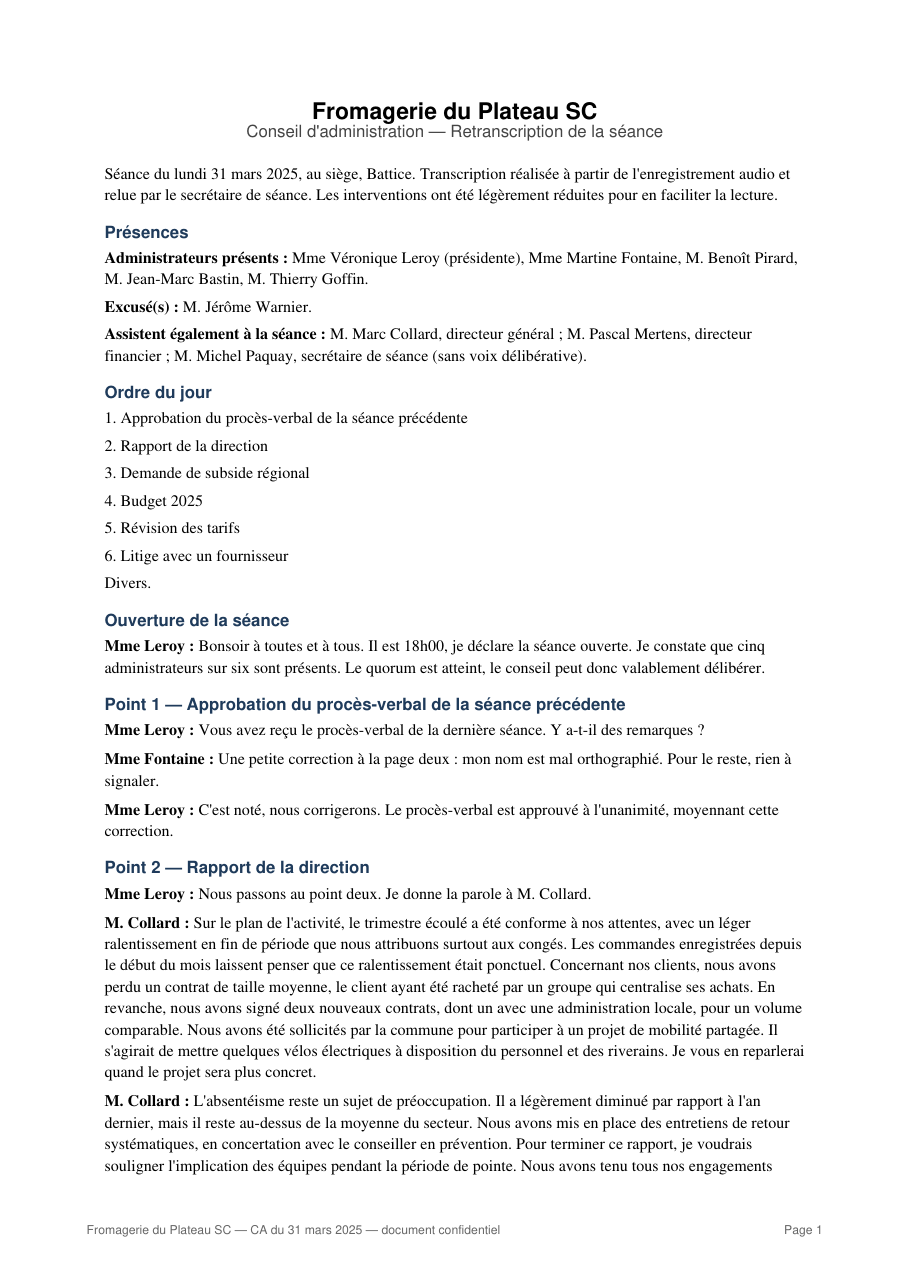

In [8]:
doc = pymupdf.open(
    "/home/bm/formation/formation/vLLM/full_llama_vllm/exos/05_pv_ca/pv_11.pdf"
)  # essayez aussi contrat_04.pdf (scan)
print(len(doc), "page(s)")

# 1) Le texte, s'il existe
texte = doc[0].get_text()
print("Scan (pas de texte)" if not texte.strip() else texte[:500])

# 2) La page en image : fonctionne dans tous les cas
pix = doc[0].get_pixmap(dpi=110)       # 110 dpi : lisible, sans exploser le nombre de tokens
png = pix.tobytes("png")
display(Image(png, width=450))

# 3) L'image prête à être envoyée au modèle (comme dans le cours sur les images)
data_uri = "data:image/png;base64," + base64.b64encode(png).decode()




In [ ]:
def resumer(chemin_pdf):
    # Ouvrir le fichier PDF
    doc = pymupdf.open(chemin_pdf)
    
    # Extraire le texte de chaque page
    texte = ""
    for page in doc:
        texte += page.get_text()
    
    # Fermer le document
    doc.close()
    
    return texte